# Green AI Data Center: Data Preparation

## Project Overview
This notebook focuses on preparing the Green AI Data Center
Telemetry Dataset for statistical analysis and modeling.

The main objectives are to:
- Examine the dataset and identify data quality issues.
- Clean and transform variables where necessary.
- Create meaningful features related to energy efficiency.
- Apply scaling and encoding when appropriate.
- Prepare the data for further analysis by the project team.

Dataset: Green AI Data Center Telemetry Dataset
Source: Deep Joshi (2026), Kaggle

In [2]:
### Libraries here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Load the dataset
df = pd.read_csv("data/green_ai_datacenter.csv")
df.head()

,server_type,cooling_type,datacenter_region,time_of_day,workload_intensity,cpu_utilization,memory_utilization,network_throughput_gbps,inlet_temperature_c,cooling_efficiency,power_consumption_kw,carbon_emission_kg,compute_cost_usd,pue,energy_efficiency_class
0,Compute,Air,APAC,Off-Peak,0.369,31.054,60.041,18.391,24.524,0.883,58.524,34.783,3.788,1.594,Low
1,Edge,Air,NaN,Off-Peak,0.185,34.425,57.542,8.076,21.944,0.951,59.946,21.333,6.735,1.473,Medium
2,GPU,Air,NaN,Night,0.214,17.188,32.198,5.057,19.726,0.961,139.775,58.925,16.039,1.619,Low
3,Storage,Liquid,EU,Peak,0.263,29.659,58.685,12.704,20.036,0.959,76.223,19.714,14.194,1.454,Medium
4,Compute,Air,EU,Off-Peak,0.283,23.086,50.790,18.460,25.290,0.923,102.655,25.609,18.259,1.394,High


From the first look at the dataset, category datacenter_region contains missing values (NaN). Will be investigated further.

Dataset has both categorical and numerical features. Use function info( ) to help determine whether the dataset contains all observations, which variables are numerical and which are categorical, which columns have missing values, and whether any variables have unexpected data types for clraning and transformation purposes.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   server_type              10000 non-null  object 
 1   cooling_type             10000 non-null  object 
 2   datacenter_region        6010 non-null   object 
 3   time_of_day              10000 non-null  object 
 4   workload_intensity       10000 non-null  float64
 5   cpu_utilization          10000 non-null  float64
 6   memory_utilization       10000 non-null  float64
 7   network_throughput_gbps  10000 non-null  float64
 8   inlet_temperature_c      10000 non-null  float64
 9   cooling_efficiency       10000 non-null  float64
 10  power_consumption_kw     10000 non-null  float64
 11  carbon_emission_kg       10000 non-null  float64
 12  compute_cost_usd         10000 non-null  float64
 13  pue                      10000 non-null  float64
 14  energy_efficiency_class

Note that there are 5 categoricalk variables, and datacenter_region is the only column with missing values, but those values are 39.90% of the category (3,990 values). Categories like energy_efficiency_class could be a potential target variable for classification, and power_consumption_kw could also be a potential outcome variable to model energy consumption. 

We will calculate exact missing number and percentage for each column next to determine how to clean the data. 

In [5]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({"Missing Count": missing_count, "Missing Percentage": missing_percent})
missing_summary

,Missing Count,Missing Percentage
server_type,0,0.0
cooling_type,0,0.0
datacenter_region,3990,39.9
time_of_day,0,0.0
workload_intensity,0,0.0
cpu_utilization,0,0.0
memory_utilization,0,0.0
network_throughput_gbps,0,0.0
inlet_temperature_c,0,0.0
cooling_efficiency,0,0.0


We must examine the distribution of the available regions to determine how best to preserve the dataset while addressing the missing information.

In [6]:
df["datacenter_region"].value_counts(dropna=False)

datacenter_region
NaN     3990
EU      3056
APAC    1966
ME       988
Name: count, dtype: int64

We will retain the missing values as a separate category to later evaluate whether missingness is associated wth other variables. A copy will be made to preserve the original dataset, and the copy will be cleaned.

In [7]:
# Create cleaned copy, make missing values an "Unknown" category
df_clean = df.copy()
df_clean["datacenter_region"] = df_clean["datacenter_region"].fillna("Unknown")
df_clean["datacenter_region"].value_counts(dropna=False) # verify replacement worked

datacenter_region
Unknown    3990
EU         3056
APAC       1966
ME          988
Name: count, dtype: int64

In [8]:
# Do any rows appear more than once?
duplicate_count = df_clean.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [9]:
# Are the numbers in reasonable ranges? Are there any outliers?
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
workload_intensity,10000.0,0.547172,0.260356,0.100,0.32000,0.5440,0.77525,1.000
cpu_utilization,10000.0,46.334781,19.409384,0.129,30.25325,46.3980,62.69175,91.754
memory_utilization,10000.0,65.723253,15.756341,5.000,54.99475,65.9430,76.74550,98.000
network_throughput_gbps,10000.0,15.469944,7.449646,1.756,10.24875,14.1170,19.34050,60.748
inlet_temperature_c,10000.0,22.034012,3.916553,15.000,19.34000,21.9105,24.48975,37.992
cooling_efficiency,10000.0,0.860706,0.095780,0.517,0.79600,0.8700,0.93600,1.000
power_consumption_kw,10000.0,82.091960,26.630186,28.169,64.18650,77.9000,95.79850,233.630
carbon_emission_kg,10000.0,33.122753,15.396742,5.069,21.86675,30.0285,41.38350,136.022
compute_cost_usd,10000.0,10.131131,4.975471,1.084,6.52975,9.3290,12.91575,42.053
pue,10000.0,1.480539,0.203365,1.050,1.35000,1.4690,1.59500,2.596


In [12]:
# Check for outliers using IQR
numeric_cols = df_clean.select_dtypes(include="number").columns

Q1 = df_clean[numeric_cols].quantile(0.25)
Q3 = df_clean[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

outliers = ((df_clean[numeric_cols] < (Q1 - 1.5 * IQR)) | (df_clean[numeric_cols] > (Q3 + 1.5 * IQR)))

outliers.sum().sort_values(ascending=False)

network_throughput_gbps    278
carbon_emission_kg         226
power_consumption_kw       209
compute_cost_usd           182
pue                        150
inlet_temperature_c        145
cooling_efficiency          35
memory_utilization          32
workload_intensity           0
cpu_utilization              0
dtype: int64

Several variables have been identified with potential outliers. Network throughput (2.78%) has the highest number of potential outliers, followed by carbon emissions (2.26%) and power consumption (2.09%). Since the percentages are relatively small, the outliers will be kept, since removing them could eliminate important examples of high energy consumption. We will examine them visually next. Network throughput, power consumption, and power usage efficiency (pue) will be looked at closer since they are relevant to this project. 

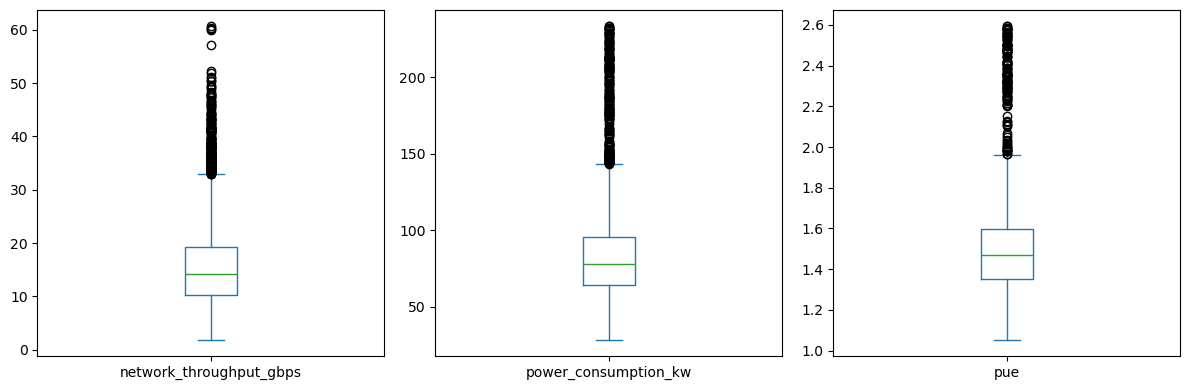

In [13]:
# Create boxplots for numeric columns to visualize outliers
columns_to_plot = ["network_throughput_gbps", "power_consumption_kw", "pue"]

df_clean[columns_to_plot].plot(kind="box", 
                               subplots=True, 
                               layout=(1, 3), 
                               figsize=(12, 4))

plt.tight_layout()
plt.show()

The boxplots confirmed the several high-end outliers, but the values reflect actual operating conditions rather than errors. They will be retained for further analysis since removing them could eliminate useful information about reduced efficiency and high energy consumption.